## EN3160 Assignment 1 on Intensity Transformation and Neighborhood Filtering

##### Name : Rasanjana W.P.G.R.A.
##### Index Number : 230536E
Github Link : [https://github.com/rus1ru/EN3160_Assignment_1](https://github.com/rus1ru/EN3160_Assignment_1)

#### 0 - Package imports

In [358]:
import cv2
import numpy as np

import matplotlib.pyplot as plt


#### Q1 : Image Transformation

In [359]:
def intensity_transform(breakpoints):
    lut = np.zeros(256, dtype=np.uint8)

    for i in range(len(breakpoints) - 1):
        x1, y1 = breakpoints[i]
        x2, y2 = breakpoints[i + 1]

        lut[x1:x2 + 1] = np.linspace(y1, y2, x2 - x1 + 1).astype(np.uint8)
            
    return lut

In [360]:
img = cv2.imread("images/q1.jpeg", 0)


# Reasoning behind breakpoints: 
# For a visual enhancement, we should increase the contrast in the mid while keeping the shadows and highlights 
breakpoints = [
    (0, 0),
    (50, 50),
    (51, 100),
    (150, 255),
    (151, 150),
    (255, 255)
]


lut = intensity_transform(breakpoints)

result = cv2.LUT(img, lut)

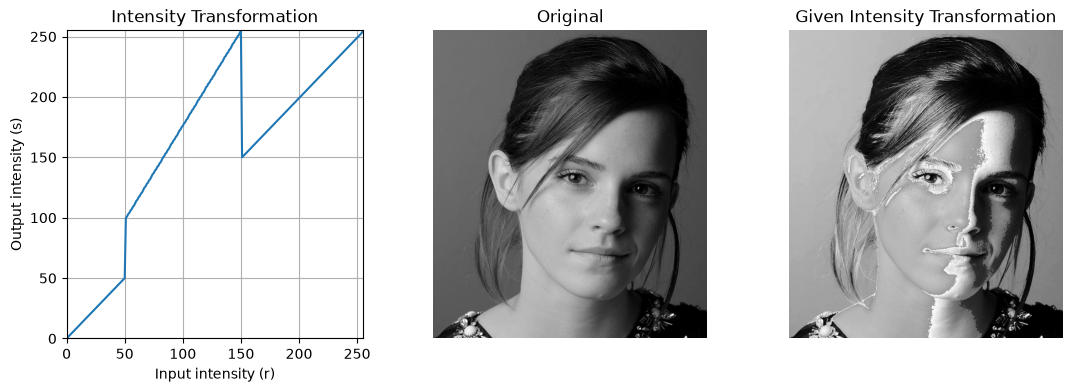

In [361]:
plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.plot(range(256), lut)
plt.xlabel("Input intensity (r)")
plt.ylabel("Output intensity (s)")
plt.title("Intensity Transformation")

plt.xlim(0, 255)
plt.ylim(0, 255)
plt.grid()

plt.subplot(1, 3, 2)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(result, cmap="gray")
plt.title("Given Intensity Transformation")
plt.axis("off")

plt.show()

Implementation and Explanation :

As we may see, ranging from 0 to 50 and 150 to 255, there's isn't any change in input and output. but from 50 to 150, there's a shift in intensity. as you may see in left side of the image there's a sudden intensity increase. that's resulting in a difference between transitional points (near 50 and 150 intensities).

In [362]:
img = cv2.imread("images/q1.jpeg", 0)


# Reasoning behind breakpoints: 
# For a visual enhancement, we should increase the contrast in the mid while keeping the shadows and highlights 
breakpoints = [
    (0, 0),
    (40, 30),
    (100, 120),
    (180, 220),
    (255, 255)
]


lut = intensity_transform(breakpoints)

result = cv2.LUT(img, lut)


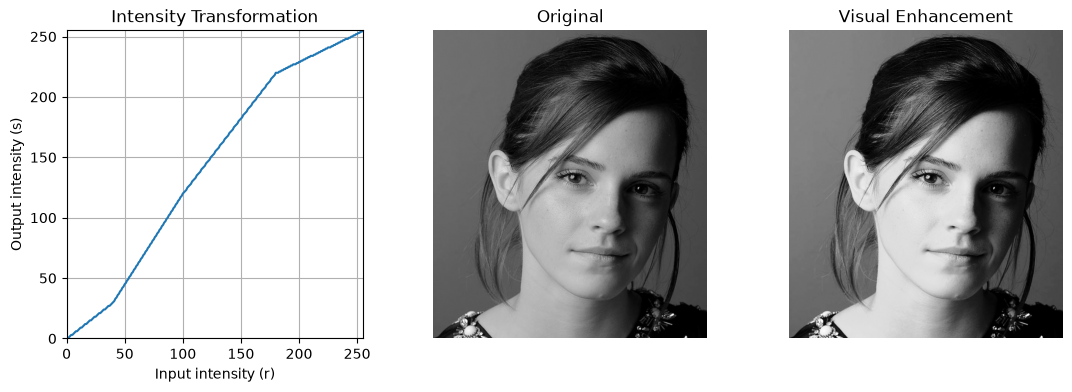

In [363]:

plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.plot(range(256), lut)
plt.xlabel("Input intensity (r)")
plt.ylabel("Output intensity (s)")
plt.title("Intensity Transformation")

plt.xlim(0, 255)
plt.ylim(0, 255)
plt.grid()

plt.subplot(1, 3, 2)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(result, cmap="gray")
plt.title("Visual Enhancement")
plt.axis("off")

plt.show()

**Explanation (Q1):**
* Smooth, monotonic S-curve : no jumps or folds.
* Shadows 0 - 40 and highlights 180–255 are compressed slightly to keep detail.
* Mid-tones 40 - 180 are expanded - where the image has most pixels, so it looks more contrast without harsh clipping.
* Overall contrast is moved from extremes to the middle, which matches how we perceive contrast.


#### Q2 : Brain Image

Intensity analysis

In [364]:
img = cv2.imread("images/q2.jpeg", 0)

hist = cv2.calcHist([img], [0], None, [256], [0, 256])

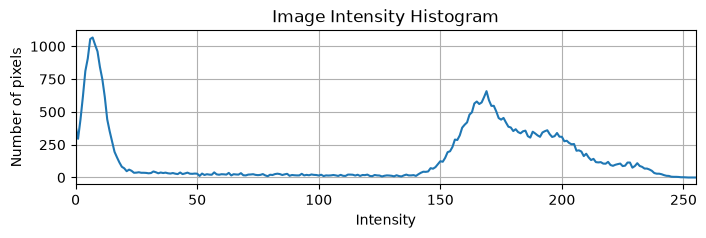

In [365]:
plt.figure(figsize=(8, 2))
plt.plot(hist)
plt.xlabel("Intensity")
plt.ylabel("Number of pixels")
plt.title("Image Intensity Histogram")
plt.xlim(0, 255)
plt.grid()
plt.show()

Explanation : We can have a Intensity Histrogram and have an idea about how intensity is throughout the image. Most of the pixels are ranging from 120 to 250. 

White Matter : Actually Darker in the image should have a lower intensity value. 
White Matter : Due to higher intensity, Use the higher band. 

In [366]:

# Reasoning behind breakpoints: 
# 
threshold_l = 175
breakpoints = [
    (0, 0),
    (threshold_l, 0),
    (threshold_l + 1, threshold_l + 1),
    (255, 255)
]

white_lut = intensity_transform(breakpoints)

result = cv2.LUT(img, white_lut)

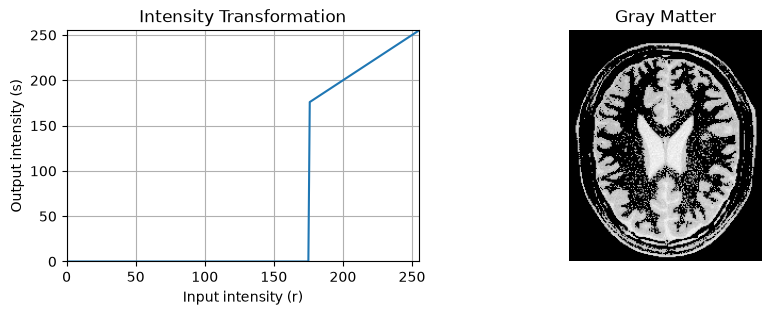

In [367]:
plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.plot(range(256), white_lut)
plt.xlabel("Input intensity (r)")
plt.ylabel("Output intensity (s)")
plt.title("Intensity Transformation")

plt.xlim(0, 255)
plt.ylim(0, 255)
plt.grid()

plt.subplot(1, 2, 2)
plt.imshow(result, cmap="gray")
plt.title("Gray Matter")
plt.axis("off")

plt.show()

In [368]:
# Reasoning behind breakpoints: 
# 
threshold_l = 120
threshold_h = 180
breakpoints = [
    (0, 0),
    (threshold_l, 0),
    (threshold_l + 1, threshold_l + 1),
    (threshold_h, threshold_h),
    (threshold_h+1, 0),
    (255, 0)
]

white_lut = intensity_transform(breakpoints)

result = cv2.LUT(img, white_lut)

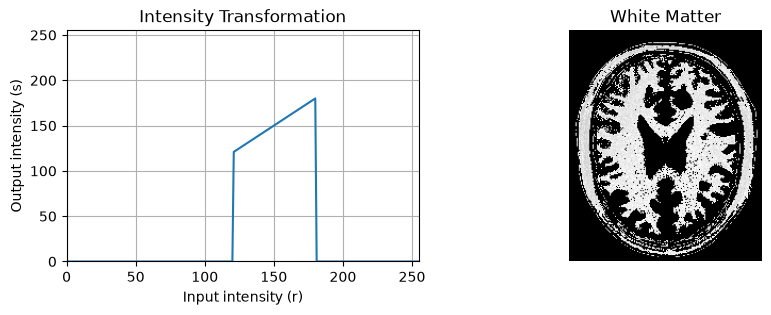

In [369]:
plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.plot(range(256), white_lut)
plt.xlabel("Input intensity (r)")
plt.ylabel("Output intensity (s)")
plt.title("Intensity Transformation")

plt.xlim(0, 255)
plt.ylim(0, 255)
plt.grid()

plt.subplot(1, 2, 2)
plt.imshow(result, cmap="gray")
plt.title("White Matter")
plt.axis("off")

plt.show()

**Explanation (Brain - white vs gray matter):**
* Tissue has two overlapping peaks - white matter ~130-180 (darker) and gray matter ~190-250 (brighter).
* We use a window LUT: 0 outside the band, identity inside. White = 120-180, Gray = 175-255 (tuned by eye). Overlap 175–180 is expected at the boundary.
* Result keeps only the chosen tissue bright; the other tissue and background become black. A soft ramp would be cleaner than a hard cut.


#### Q3 : Gamma Correction

In [370]:
def gamma_correct_L(image, gamma=1):
    # BGR -> LAB
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    # Split channels
    L, a, b = cv2.split(lab)

    # Normalize
    L_float = L.astype(np.float32) / 255.0

    # Gamma correction
    L_corrected = np.power(L_float, gamma) * 255.0

    # Convert back to uint8
    L_corrected = np.clip(L_corrected, 0, 255).astype(np.uint8)

    lab_corrected = cv2.merge([L_corrected, a, b])
    result = cv2.cvtColor(lab_corrected, cv2.COLOR_LAB2BGR)

    return result

In [371]:
img = cv2.imread("images/q3.jpeg")
corrected = gamma_correct_L(img, gamma=0.5)

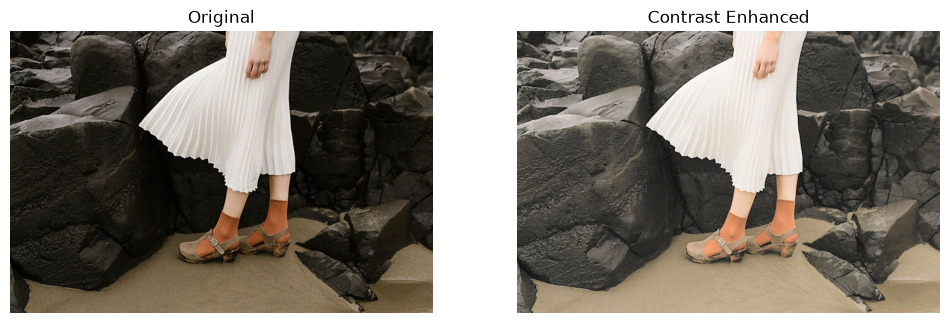

In [372]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(corrected, cv2.COLOR_BGR2RGB))
plt.title("Contrast Enhanced")
plt.axis("off")

plt.show()

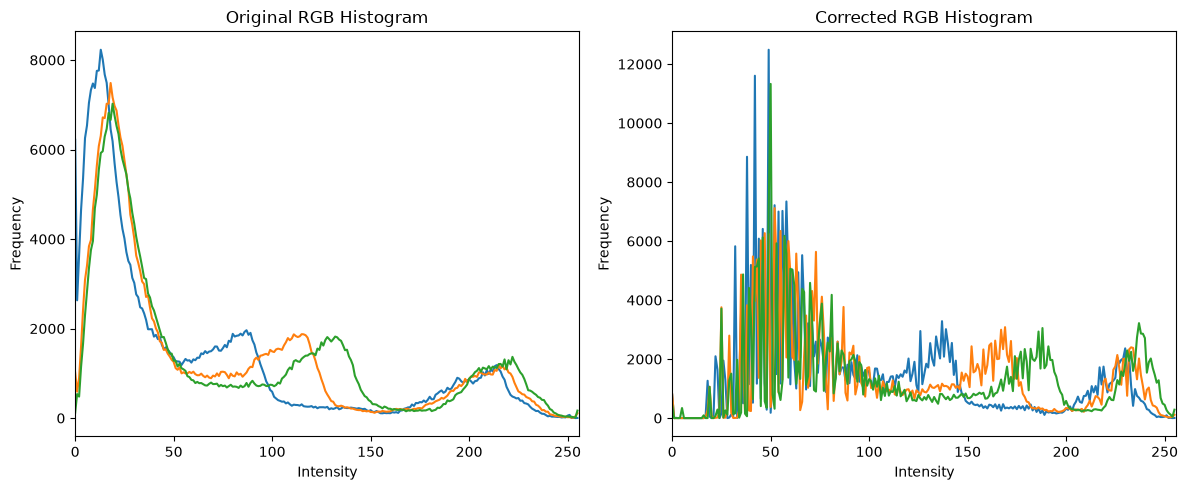

In [373]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

for channel in range(3):
    hist = cv2.calcHist([img], [channel], None, [256], [0, 256])
    plt.plot(hist)

plt.title("Original RGB Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])

plt.subplot(1, 2, 2)

for channel in range(3):
    hist = cv2.calcHist([corrected], [channel], None, [256], [0, 256])
    plt.plot(hist)

plt.title("Corrected RGB Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

**Explanation (Gamma correction on L):**
* We work on L in La*b* so only brightness changes - hue (a*, b*) stays fixed.
* Gamma 0.5 (square root: output = input^0.5) lifts shadows and mid-tones, making stone texture visible. Gamma >1 would darken.
* Histograms: original is left-heavy (shadows); after correction the middle moves right by ~30-50 levels.
* 0.5 is a good balance here; below ~0.4 highlights wash out and noise in darks gets louder.


#### Q4 : Increasing the vibrance using a intensity transfomation

In [374]:
def intensity_transform_saturation(image, a=0, sigma=70):
    # BGR -> HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Split channels
    h, s, v = cv2.split(hsv)

    # Normalize
    s_float = s.astype(np.float32)

    s_corrected = (
        s_float
        + a * 128 * np.exp(
            -((s_float - 128) ** 2) / (2 * sigma ** 2)
        )
    )

    # Convert back to uint8
    s_corrected = np.clip(s_corrected, 0, 255).astype(np.uint8)

    hsv_corrected = cv2.merge([h, s_corrected, v])
    result = cv2.cvtColor(hsv_corrected, cv2.COLOR_HSV2BGR)

    return result

In [375]:
x = np.arange(256, dtype=np.float32)

a = 0.65
y = (
    x
    + a * 128 * np.exp(
        -((x - 128) ** 2) / (2 * 70 ** 2)
    )
)

y = np.clip(y, 0, 255)

In [376]:
img = cv2.imread("images/q4.jpeg")
corrected = intensity_transform_saturation(img, a=0.65)

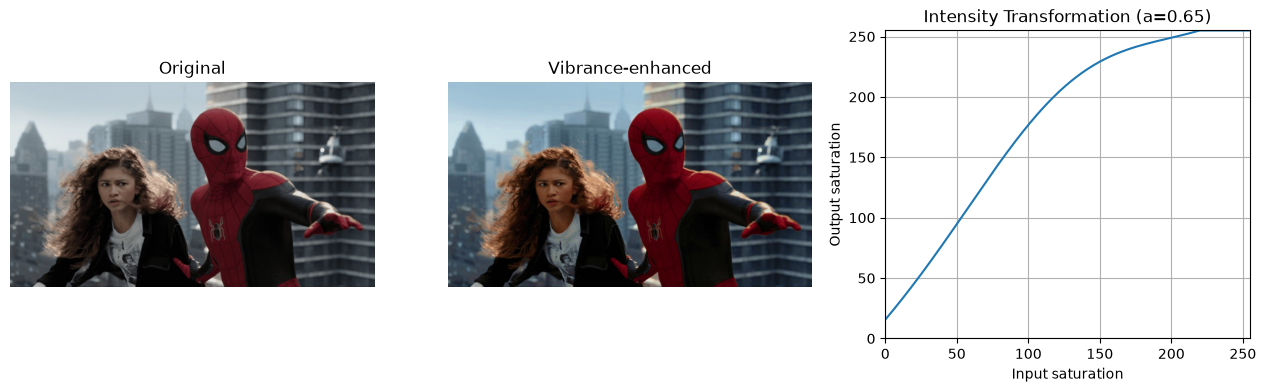

In [377]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(corrected, cv2.COLOR_BGR2RGB))
plt.title("Vibrance-enhanced")
plt.axis("off")



plt.subplot(1, 3, 3)
plt.plot(x, y)

plt.xlabel("Input saturation")
plt.ylabel("Output saturation")
plt.title(f"Intensity Transformation (a={a})")

plt.xlim(0, 255)
plt.ylim(0, 255)

plt.grid()
plt.show()

**Explanation (Vibrance - Q4):**
* We work on S in HSV so hue and brightness stay fixed. sigma=70 sets bump width; a controls strength.
* a=0.65 was tuned visually: below ~0.4 effect is weak, above ~0.8 skin/sky look over-saturated. At 0.65 mid-saturation rises most while low/high S barely move.

#### Q5 : Histrogram  Equalization

In [378]:
def histrogram_equalization(img):
    # histrogram calculation usign calcHist function
    hist = cv2.calcHist([img], [0], None, [256], [0, 256])
    cdf = hist.cumsum()

    # Normalize the CDF
    cdf_normalized = cdf / cdf[-1]

    L = 256
    mapping = np.round((L - 1) * cdf_normalized).astype(np.uint8)

    # Apply the mapping to the image
    result = cv2.LUT(img, mapping)

    hist_after = cv2.calcHist([result], [0], None, [256], [0, 256])

    return result, hist, hist_after

In [379]:
img = cv2.imread("images/shells.tif", 0)
corrected, before_hist, after_hist = histrogram_equalization(img)

[ WARN:0@6852.201] global grfmt_tiff.cpp:123 TIFF_Warning TIFFFetchNormalTag: ASCII value for tag "ImageDescription" does not end in null byte. Forcing it to be null


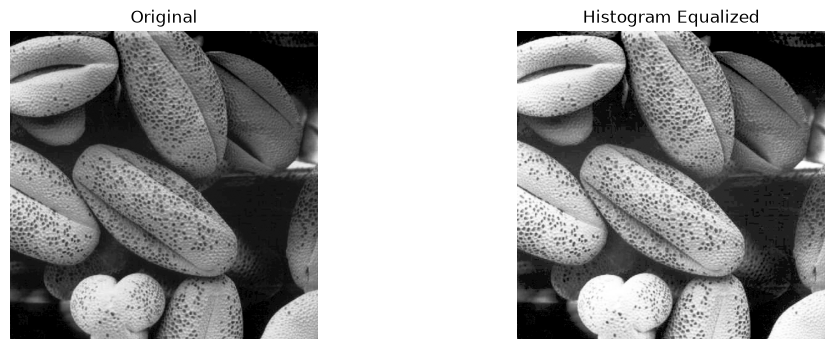

In [380]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(corrected, cmap="gray")
plt.title("Histogram Equalized")
plt.axis("off")

plt.show()

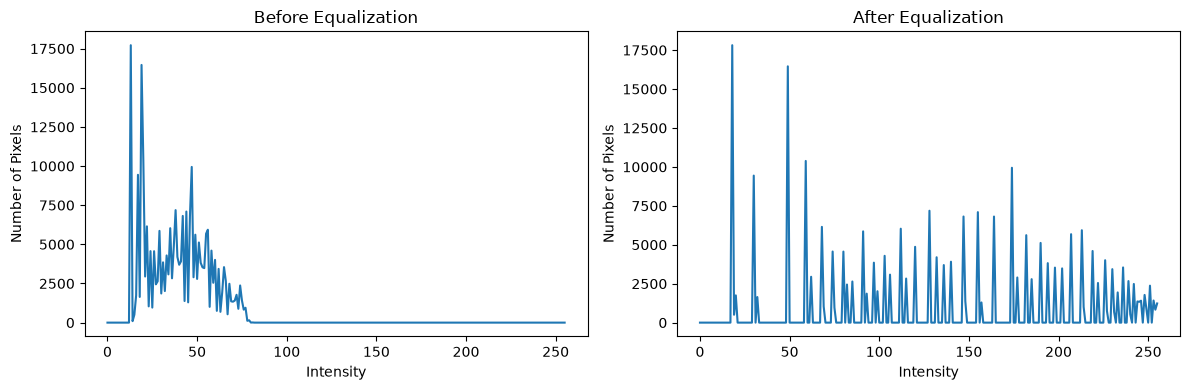

In [381]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(before_hist)
plt.title("Before Equalization")
plt.xlabel("Intensity")
plt.ylabel("Number of Pixels")

plt.subplot(1, 2, 2)
plt.plot(after_hist)
plt.title("After Equalization")
plt.xlabel("Intensity")
plt.ylabel("Number of Pixels")

plt.tight_layout()
plt.show()

**Explanation (Histogram equalization - Q5):**
* Steps: 256-bin histogram → CDF → normalize to [0,1] → map = 255×CDF → apply with LUT.
* This spreads common intensities over more levels, so the histogram looks flatter and the image uses the full 0-255 range.
* Drawback: global - a large background peak can dominate and flat areas may show more noise. Q6 fixes this by using only the foreground.


#### Q5 : Histrogram Equaliztion only for the foreground

In [382]:
def histrogram_equalization_hsv_visualization(img):

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    h, s, v = cv2.split(hsv)


    threshold = 15

    _, mask = cv2.threshold(
        s,
        threshold,
        255,
        cv2.THRESH_BINARY
    )
    
    return h,s,v,mask

In [383]:
def histrogram_equalization_mask(img, s, mask):
    # histrogram calculation usign calcHist function

    foreground = cv2.bitwise_and(s, s, mask=mask)
    background = cv2.bitwise_and(s, s, mask=cv2.bitwise_not(mask))

    # Compute histogram of foreground saturation
    hist = cv2.calcHist(
        [foreground],
        [0],
        mask,
        [256],
        [0, 256]
    )
    n = np.sum(hist)
    p = hist / n
    cdf = np.cumsum(p)

    # Normalize the CDF
    cdf_normalized = cdf / cdf[-1]

    L = 256
    mapping = np.round((L - 1) * cdf_normalized).astype(np.uint8)

    foreground_equalized = np.zeros_like(s)

    foreground_equalized[mask > 0] = cv2.LUT(foreground[mask > 0], mapping)

    result_s = cv2.add(foreground_equalized, background)
    result_hsv = cv2.merge([h, result_s, v])
    result = cv2.cvtColor(result_hsv, cv2.COLOR_HSV2BGR)

    hist_after = cv2.calcHist([result], [0], None, [256], [0, 256])

    return result, hist, hist_after

In [384]:
img = cv2.imread("images/q6.jpeg")
h, s, v, mask = histrogram_equalization_hsv_visualization(img)
result, before_hist, after_hist = histrogram_equalization_mask(img, s, mask)
# From our output, to get a mask of foreground we have to go with Saturation channel.

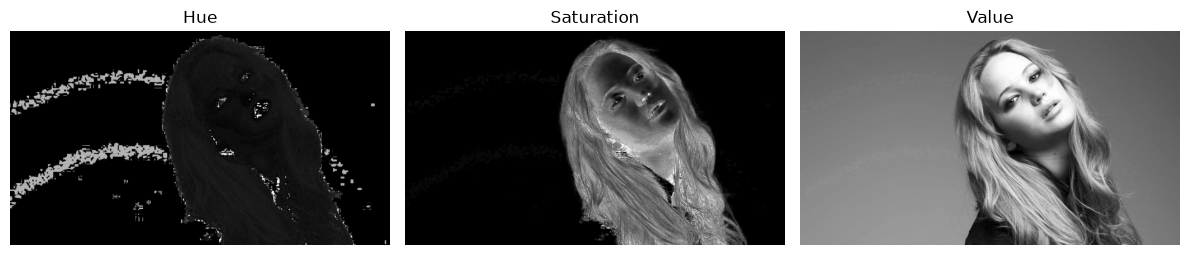

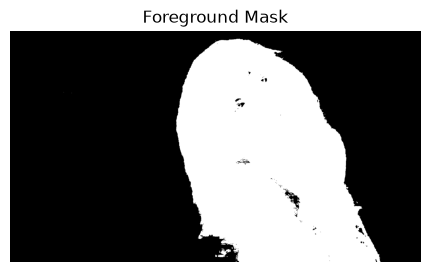

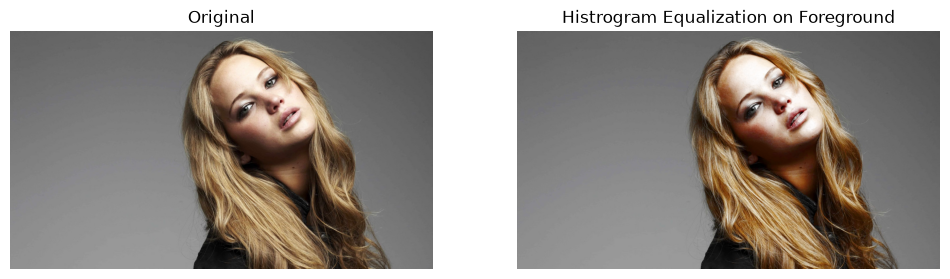

In [385]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(h, cmap="gray")
plt.title("Hue")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(s, cmap="gray")
plt.title("Saturation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(v, cmap="gray")
plt.title("Value")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 3))
plt.imshow(mask, cmap="gray")
plt.title("Foreground Mask")
plt.axis("off")
plt.show()

plt.figure(figsize=(12, 8))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Histrogram Equalization on Foreground")
plt.axis("off")

plt.show()

**Explanation (Foreground only : Q6):**
* Split to HSV: H is noisy in white areas, V mixes shading and background brightness - S is cleanest. Background S is 0-15 (white) .
* Threshold S > 15 gives the mask. Histogram is computed only where mask = 1, so background does not affect the CDF.
* Only foreground S is remapped via LUT; background S is copied unchanged, then merged back with original H, V.
* Result: foreground colours have more contrast, background stays white.


#### Q7.a : Filtering with the Sobel Operator

In [386]:
def filter_through_filter2D(image):

    sobel_x_kernel = np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1]
    ], dtype=np.float32)

    # cv2.CV_32F is used to specify the desired depth of the output image. It indicates that the output image should have a depth of 32-bit floating-point numbers. This is important because the Sobel filter can produce negative values, and using a floating-point representation allows for a wider range of values, including negative ones, which can be useful for edge detection.
    result = cv2.filter2D(image, cv2.CV_32F, sobel_x_kernel)

    return result

In [387]:
def filter_through_from_scratch(image):

    sobel_x_kernel = np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1]
    ], dtype=np.float32)

    x, y = image.shape

    padded_img = np.pad(
        image,
        ((1, 1), (1, 1)),
        mode='constant'
    )

    result = np.zeros_like(image, dtype=np.float32)

    for i in range(x):
        for j in range(y):
            region = padded_img[i:i+3, j:j+3]

            result[i, j] = np.sum(region * sobel_x_kernel)

    return (result)

In [388]:
def filter_through_1D_convo(image):
    sobel_x_kernel = np.array([-1, 0, 1], dtype=np.float32)
    sobel_y_kernel = np.array([1, 2, 1], dtype=np.float32)

    x, y = image.shape


    result_x = np.zeros_like(image, dtype=np.float32)
    result_y = np.zeros_like(image, dtype=np.float32)

    for i in range(x):
        for j in range(1, y - 1):
            result_x[i, j] = np.sum(
                image[i, j-1:j+2] * sobel_x_kernel
            )

    for i in range(1, x - 1):
        for j in range(y):
            result_y[i, j] = np.sum(
                result_x[i-1:i+2, j] * sobel_y_kernel
            )

    return (result_y)

In [389]:
img_ein = cv2.imread("images/q7.jpeg", 0)
result_filter = filter_through_filter2D(img_ein)
result_handwritten = filter_through_from_scratch(img_ein)
result_from_scratch_1D = filter_through_1D_convo(img_ein)
# From our output, to get a mask of foreground we have to go with Saturation channel.

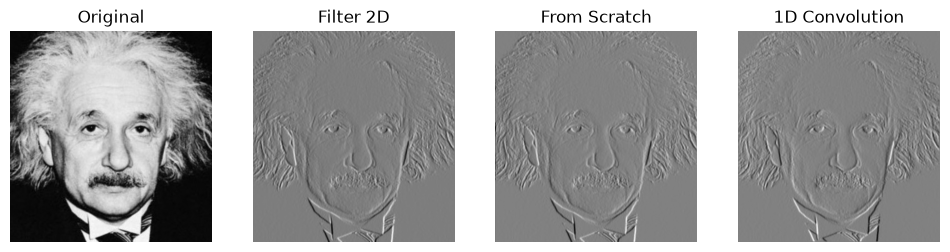

In [390]:
plt.figure(figsize=(12, 8))

plt.subplot(1, 4, 1)
plt.imshow(img_ein, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(result_filter, cmap="gray")
plt.title("Filter 2D")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(result_handwritten, cmap="gray")
plt.title("From Scratch")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(result_from_scratch_1D, cmap="gray")
plt.title("1D Convolution")
plt.axis("off")

plt.show()

**Explanation (Sobel filtering - Q7):**
* Sobel Gx finds vertical edges: smoothing [1,2,1] across rows and derivative [-1,0,1] across columns.
* Three versions give the same interior: (a) cv2.filter2D (reference, CV_32F keeps negative values), (b) direct 3×3 loop, (c) separable two 1D passes (`[1,2,1]ᵀ·[-1,0,1]`).
* Separable is ~30% fewer multiplies and shows the same edge map. The only visible difference is the 1-px border: 1D keeps 0, filter2D replicates the edge.


#### Q8 : Programming to do zooming

In [391]:
def nearest_neighbor_interpolation(image, scale_factor):

    h, w, c = image.shape
    new_h, new_w = int(h * scale_factor), int(w * scale_factor)
    result = np.zeros((new_h, new_w, c), dtype=image.dtype)

    for i in range(new_h):
        for j in range(new_w):
            orig_i = min(int(i / scale_factor), h - 1)
            orig_j = min(int(j / scale_factor), w - 1)
            result[i, j] = image[orig_i, orig_j]

    return result

In [392]:
def bilinear_interpolation(image, scale_factor):
    if image.ndim == 2:
        h, w = image.shape
        c = None
        image_f = image.astype(np.float32)
    else:
        h, w, c = image.shape
        image_f = image.astype(np.float32)
    new_h, new_w = int(round(h * scale_factor)), int(round(w * scale_factor))
    if c is None:
        result = np.zeros((new_h, new_w), dtype=np.float32)
    else:
        result = np.zeros((new_h, new_w, c), dtype=np.float32)
    for i in range(new_h):
        y = (i + 0.5) / scale_factor - 0.5
        y = np.clip(y, 0, h - 1)
        y0 = int(np.floor(y)); y1 = min(y0 + 1, h - 1); dy = y - y0
        for j in range(new_w):
            x = (j + 0.5) / scale_factor - 0.5
            x = np.clip(x, 0, w - 1)
            x0 = int(np.floor(x)); x1 = min(x0 + 1, w - 1); dx = x - x0
            if c is None:
                result[i, j] = (1-dy)*(1-dx)*image_f[y0, x0] + (1-dy)*dx*image_f[y0, x1] + dy*(1-dx)*image_f[y1, x0] + dy*dx*image_f[y1, x1]
            else:
                result[i, j] = (1-dy)*(1-dx)*image_f[y0, x0] + (1-dy)*dx*image_f[y0, x1] + dy*(1-dx)*image_f[y1, x0] + dy*dx*image_f[y1, x1]
    return np.clip(result, 0, 255).astype(image.dtype)


In [393]:
def normalized_ssd(image1, image2):
    # Compute the sum of squared differences
    ssd = np.sum((image1.astype(np.float32) - image2.astype(np.float32)) ** 2)

    # Normalize by the number of pixels
    normalized_ssd_value = ssd / (image1.shape[0] * image1.shape[1])

    return normalized_ssd_value

In [394]:
img_1 = cv2.imread("images/im01small.png")
img_2 = cv2.imread("images/im02small.png")
img_1_original = cv2.imread("images/im01.png")
img_2_original = cv2.imread("images/im02.png")

img_1_nearest_neighbour = nearest_neighbor_interpolation(img_1, 4)
img_2_nearest_neighbour = nearest_neighbor_interpolation(img_2, 4)
img_1_bilinear = bilinear_interpolation(img_1, 4)
img_2_bilinear = bilinear_interpolation(img_2, 4)


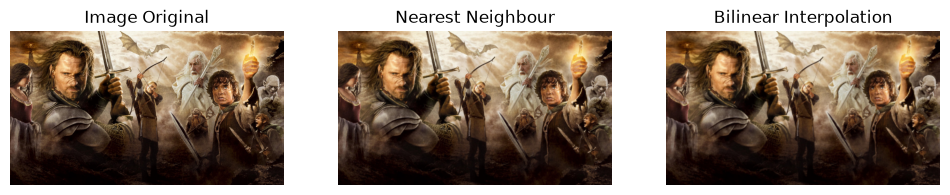

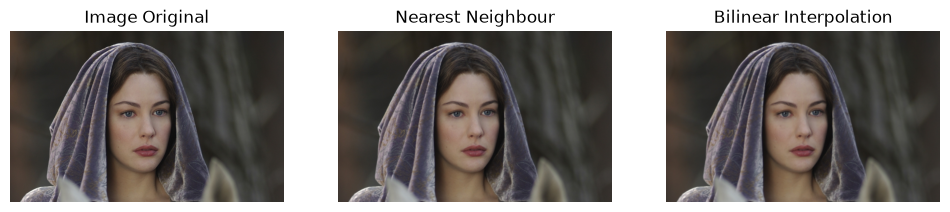

In [395]:
plt.figure(figsize=(12, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img_1_original, cv2.COLOR_BGR2RGB))
plt.title("Image Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_1_nearest_neighbour, cv2.COLOR_BGR2RGB))
plt.title("Nearest Neighbour")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_1_bilinear, cv2.COLOR_BGR2RGB))
plt.title("Bilinear Interpolation")
plt.axis("off")

plt.show()

plt.figure(figsize=(12, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img_2_original, cv2.COLOR_BGR2RGB))
plt.title("Image Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(img_2_nearest_neighbour, cv2.COLOR_BGR2RGB))
plt.title("Nearest Neighbour")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_2_bilinear, cv2.COLOR_BGR2RGB))
plt.title("Bilinear Interpolation")
plt.axis("off")

plt.show()

In [396]:
# Quantitative comparison using normalized SSD

ssd_nearest_1 = normalized_ssd(img_1_original, img_1_nearest_neighbour)
ssd_bilinear_1 = normalized_ssd(img_1_original, img_1_bilinear)

ssd_nearest_2 = normalized_ssd(img_2_original, img_2_nearest_neighbour)
ssd_bilinear_2 = normalized_ssd(img_2_original, img_2_bilinear)

print(f"Image 1 - Nearest Neighbour SSD: {ssd_nearest_1:.4f}, Bilinear SSD: {ssd_bilinear_1:.4f}")
print(f"Image 2 - Nearest Neighbour SSD: {ssd_nearest_2:.4f}, Bilinear SSD: {ssd_bilinear_2:.4f}")

Image 1 - Nearest Neighbour SSD: 408.8071, Bilinear SSD: 345.3790
Image 2 - Nearest Neighbour SSD: 79.3383, Bilinear SSD: 55.1896


**Explanation (Zooming - Q8, fixed):**

* After fix nearest 408.8 / bilinear 345.4 - bilinear is better (smoother, less aliasing). In pixel range this 136 / 115 per-pixel.
* Visually bilinear is preferred even though SSD still penalises its slight blur.


#### Q9 : Image editing using GrabCut and Blurring

In [397]:
def segment_through_grabcut(image):
    mask = np.zeros(image.shape[:2],np.uint8)
    bgdModel = np.zeros((1,65),np.float64)
    fgdModel = np.zeros((1,65),np.float64)

    rect = (50,140,550,500)  # get the rectangle coordinates relatively by adjusting

    cv2.grabCut(image,mask,rect,bgdModel,fgdModel,10,cv2.GC_INIT_WITH_RECT)
    mask2 = np.where((mask==2)|(mask==0),0,1).astype('uint8')

    foreground = image*mask2[:,:,np.newaxis]
    background = image*(1-mask2[:,:,np.newaxis])

    return mask2, foreground, background

In [398]:
img = cv2.imread("images/q8.jpeg")
mask2, foreground, background = segment_through_grabcut(img)

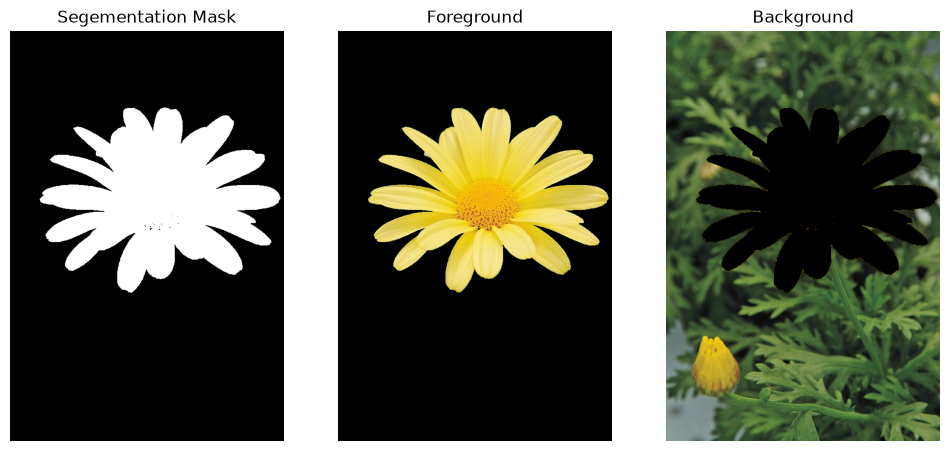

In [399]:
plt.figure(figsize=(12, 8))

plt.subplot(1, 3, 1)
plt.imshow(mask2, cmap="gray")
plt.title("Segementation Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(foreground, cv2.COLOR_BGR2RGB))
plt.title("Foreground")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(background, cv2.COLOR_BGR2RGB))
plt.title("Background")
plt.axis("off")

plt.show()

In [400]:
background_blurred = cv2.GaussianBlur(background, (45, 45), 0)

result = cv2.add(foreground, background_blurred)

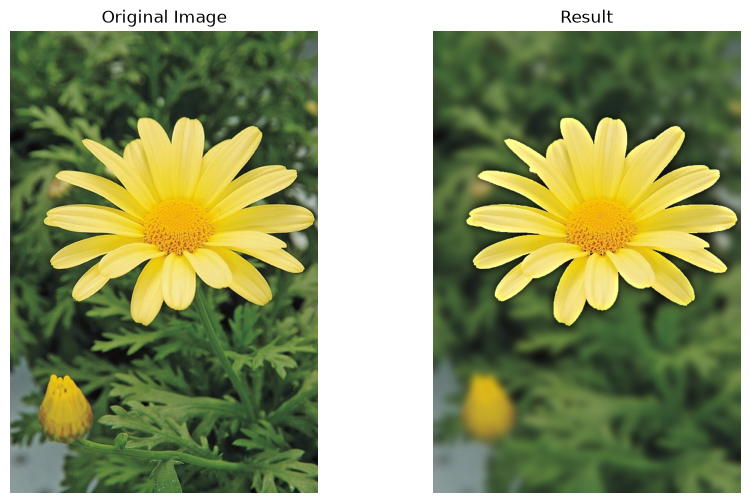

In [401]:
plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Result")
plt.axis("off")

plt.show()

**Explanation on Q9 :**
* GrabCut is started with a rectangle (50,140,550,500) around the flower and 10 iterations ,enough for a clean mask.
* Mask gives foreground and background; background is blurred with a large Gaussian (45 x 45) to mimic depth of field while the flower stays sharp.
* Why a dark ring just beyond the petals? Background there is black (0) because we cut with image*(1-mask). Blurring mixes that black into nearby pixels. Better: blur the whole original, then combine foreground + blurred_original·(1-mask).


#### Q10 : Bilateral Filter on Lake Minaret

In [402]:
img = cv2.imread("images/q9.jpeg")

kernel_size = 9
sigma_s = 80
sigma_r = 80

gaussian = cv2.GaussianBlur(img,(kernel_size, kernel_size),sigmaX=sigma_s)

bilateral = cv2.bilateralFilter(img, d=kernel_size, sigmaColor=sigma_r, sigmaSpace=sigma_s )

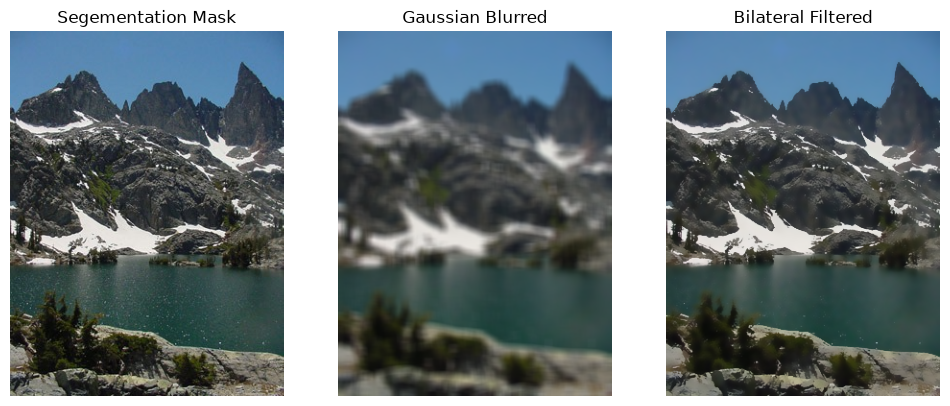

In [403]:
plt.figure(figsize=(12, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Segementation Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(gaussian, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Blurred")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(bilateral, cv2.COLOR_BGR2RGB))
plt.title("Bilateral Filtered")
plt.axis("off")

plt.show()

In [404]:
def bilateral_filter_implementation(image, kernel_size=9, sigma_s=75, sigma_r=75):

    image = image.astype(np.float32)

    pad = kernel_size // 2

    padded = np.pad(
        image,
        ((pad, pad), (pad, pad), (0, 0)),
        mode="reflect"
    )

    output = np.zeros_like(image)


    x, y = np.meshgrid(
        np.arange(-pad, pad + 1),
        np.arange(-pad, pad + 1)
    )

    spatial_weight = np.exp(
        -(x**2 + y**2) / (2 * sigma_s**2)
    )

    # Bilateral filtering equation implementation (Based on Lecture Slide)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            # Neighborhood Ω
            neighborhood = padded[
                i:i + kernel_size,
                j:j + kernel_size
            ]

            # I(x)
            center = image[i, j]

            # I(xi) - I(x)
            difference = neighborhood - center

            # ||I(xi) - I(x)||²
            color_distance_squared = np.sum(
                difference ** 2,
                axis=2
            )

            # G_sigma_r(||I(xi) - I(x)||)
            range_weight = np.exp(
                -color_distance_squared /
                (2 * sigma_r**2)
            )

            # Combined weight
            weights = spatial_weight * range_weight

            # W_p
            Wp = np.sum(weights)

            # Weighted sum
            output[i, j] = np.sum(
                weights[:, :, np.newaxis] * neighborhood,
                axis=(0, 1)
            ) / Wp

    return np.clip(output, 0, 255).astype(np.uint8)

In [405]:
img = cv2.imread("images/q9.jpeg")

kernel_size = 9
sigma_s = 80
sigma_r = 80


bilateral_new = bilateral_filter_implementation(img, kernel_size=kernel_size, sigma_s=sigma_s, sigma_r=sigma_r)

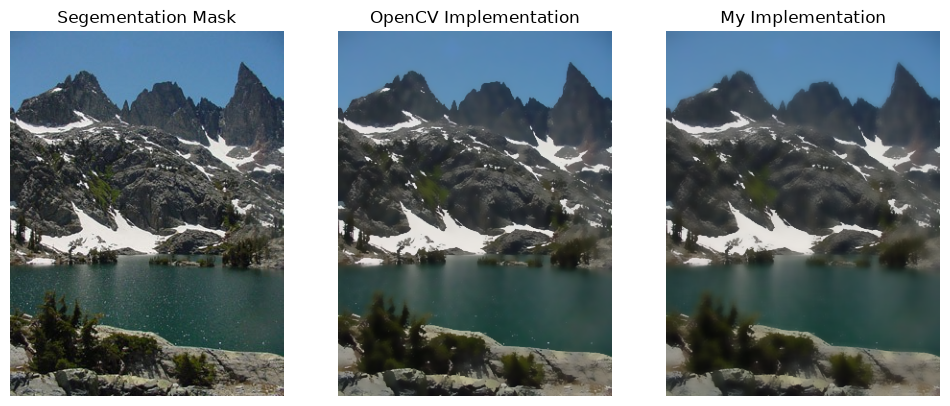

In [406]:
plt.figure(figsize=(12, 8))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Segementation Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(bilateral, cv2.COLOR_BGR2RGB))
plt.title("OpenCV Implementation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(bilateral_new, cv2.COLOR_BGR2RGB))
plt.title("My Implementation")
plt.axis("off")

plt.show()

##### Q10.b : Comparing the images quantitavely 

In [407]:
bilateral_new_f = bilateral_new.astype(np.float32)
bilateral_opencv_f = bilateral.astype(np.float32)

mse = np.mean((bilateral_new_f - bilateral_opencv_f) ** 2)
mae = np.mean(np.abs(bilateral_new_f - bilateral_opencv_f))
max_error = np.max(np.abs(bilateral_new_f - bilateral_opencv_f))

print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"Max error: {max_error:.0f}")

MSE: 31.2251
MAE: 3.2631
Max error: 66


**Explanation (Bilateral filtering — Q10):**
* Goal: smooth texture but keep edges. Gaussian smooths everything; bilateral weights by both distance (sigma_s) and colour difference (sigma_r).
* Chose kernel 9, sigma_s = 80, sigma_r = 80 : large enough to denoise flat water/sky, but still preserves strong edges like the shoreline.
* To check our implementation and OpenCV implementation,MSE/MAE between the two implementations is the right check.